In [7]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
RANDOM_SEED = 67

# Existing regional feature dataset generated in Notebook 06
FEATURES_PATH = Path("../data/processed/region_features.csv")

# Original training annotations for whole-image PASS/FAIL labels
TRAIN_COCO_PATH = Path(
    "../data/raw/train/_annotations.coco.json"
)

# Saved neural network and image failure criterion
MODEL_PATH = Path("../models/binary_region_nn.joblib")
THRESHOLD_PATH = Path("../models/binary_region_nn_threshold.json")

# Six input features used in our previous regional classifier
FEATURE_COLS = [
    "mean_r", "mean_g", "mean_b",
    "std_r", "std_g", "std_b"
]


In [8]:
# Load the previously extracted 32×32 region features.
df = pd.read_csv(FEATURES_PATH)

# Separate input features from binary defect labels.
X_train = df[FEATURE_COLS]
y_train = df["label"].astype(int)

# Confirm there are no missing feature values.
assert not X_train.isnull().any().any(), \
    "Missing values detected in the input features."

# Confirm the target labels are strictly binary.
assert set(y_train.unique()) == {0, 1}, \
    "Expected binary labels containing both 0 and 1."

print(f"Training regions: {len(df):,}")
print(f"Original images: {df['image_id'].nunique()}")
print(f"Input features: {X_train.shape[1]}")

print("\nRegion label distribution:")
print(y_train.value_counts().sort_index())


Training regions: 1,301,541
Original images: 3349
Input features: 6

Region label distribution:
label
0    1236046
1      65495
Name: count, dtype: int64


### Load Regional Training Data


In [9]:

# Construct a pipeline containing feature standardisation
# followed by a fully connected neural network classifier.
nn_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        MLPClassifier(
            # Two hidden layers with 32 and 16 neurons.
            hidden_layer_sizes=(32, 16),

            # ReLU activation for the hidden layers.
            activation="relu",

            # Adam optimiser updates network weights.
            solver="adam",

            # L2 regularisation to reduce overfitting.
            alpha=0.0001,

            # Initial learning rate.
            learning_rate_init=0.001,

            # Maximum number of training epochs.
            max_iter=500,

            # Stop training when improvement becomes small.
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,

            # Fix random initialisation for reproducibility.
            random_state=RANDOM_SEED
        )
    )
])

print("Binary neural network constructed successfully.")


Binary neural network constructed successfully.


### Train Binary NN Classifier

In [10]:

import time

# Record the starting time.
start_time = time.time()

# Fit the scaler and train the neural network
# using the six RGB features and binary defect labels.
nn_pipeline.fit(X_train, y_train)

# Calculate total training time.
training_time = time.time() - start_time

# Access the trained classifier.
nn_model = nn_pipeline.named_steps["classifier"]

print("Training complete.")
print(f"Training time: {training_time:.2f} seconds")
print(f"Training epochs: {nn_model.n_iter_}")
print(f"Final training loss: {nn_model.loss_:.5f}")


Training complete.
Training time: 126.20 seconds
Training epochs: 61
Final training loss: 0.10413


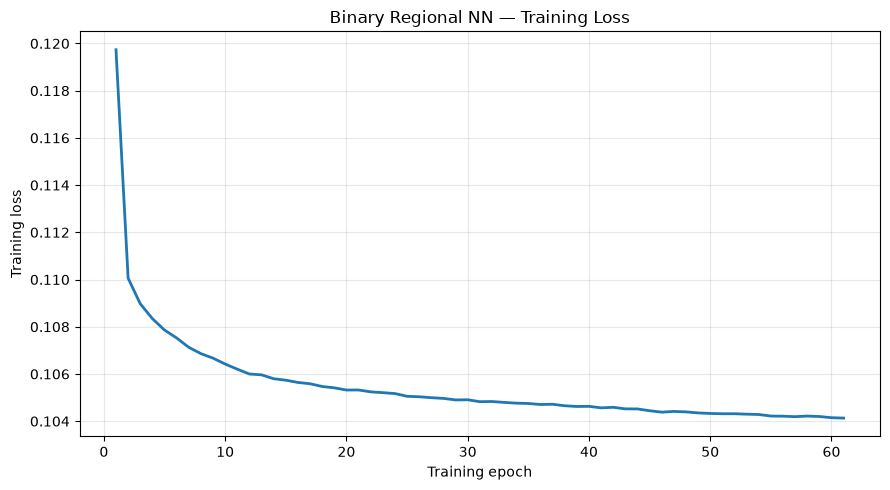

In [11]:

# Retrieve the loss recorded after each training epoch.
loss_history = nn_model.loss_curve_

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    linewidth=2
)

plt.xlabel("Training epoch")
plt.ylabel("Training loss")
plt.title("Binary Regional NN — Training Loss")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Region training accuracy: 95.95%
Region balanced accuracy: 64.51%

Region classification report:
              precision    recall  f1-score   support

  NON-DEFECT      0.964     0.995     0.979   1236046
      DEFECT      0.745     0.296     0.423     65495

    accuracy                          0.959   1301541
   macro avg      0.854     0.645     0.701   1301541
weighted avg      0.953     0.959     0.951   1301541



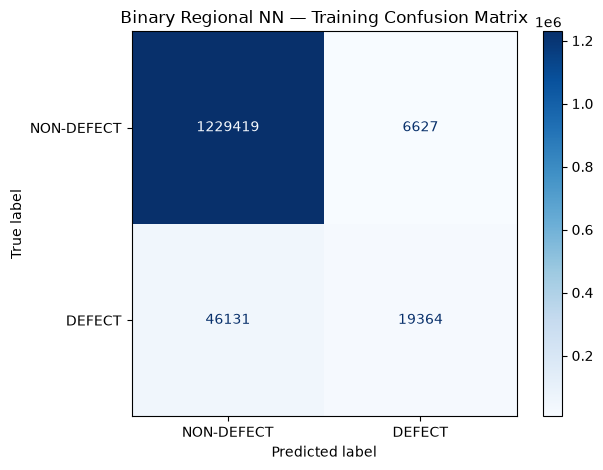

In [12]:

# Generate strict binary classifications for training regions.
# 0 = NON-DEFECT, 1 = DEFECT
y_train_pred = nn_pipeline.predict(X_train)

# Verify that the predictions contain only binary values.
assert set(np.unique(y_train_pred)).issubset({0, 1})

# Calculate training classification metrics.
train_accuracy = accuracy_score(y_train, y_train_pred)

train_balanced_accuracy = balanced_accuracy_score(
    y_train, y_train_pred
)

print(f"Region training accuracy: {train_accuracy:.2%}")
print(f"Region balanced accuracy: {train_balanced_accuracy:.2%}")

print("\nRegion classification report:")
print(
    classification_report(
        y_train,
        y_train_pred,
        labels=[0, 1],
        target_names=["NON-DEFECT", "DEFECT"],
        zero_division=0,
        digits=3
    )
)

# Generate a region-level confusion matrix.
cm = confusion_matrix(
    y_train,
    y_train_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NON-DEFECT", "DEFECT"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Binary Regional NN — Training Confusion Matrix")
plt.tight_layout()
plt.show()


### Recombine regions into original images

In [13]:

# Create a DataFrame containing the original image identifiers
# and the predicted binary classification of each region.
region_predictions_df = df[
    ["image_id", "filename"]
].copy()

# Store the neural network's binary region predictions.
region_predictions_df["predicted_defect"] = y_train_pred

# Group the region predictions by original image.
image_predictions_df = (
    region_predictions_df
    .groupby(["image_id", "filename"], as_index=False)
    .agg(
        # Sum binary predictions to count defective regions.
        predicted_defect_count=("predicted_defect", "sum"),

        # Count the total number of retained regions per image.
        total_regions=("predicted_defect", "size")
    )
)

# Calculate the proportion of retained regions classified defective.
image_predictions_df["defective_region_fraction"] = (
    image_predictions_df["predicted_defect_count"]
    / image_predictions_df["total_regions"]
)

print(
    f"Training images reconstructed: "
    f"{len(image_predictions_df)}"
)

display(image_predictions_df.head(10))


Training images reconstructed: 3349


,image_id,filename,predicted_defect_count,total_regions,defective_region_fraction
0,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,1,389,0.002571
1,1,frame_with_red_1237_jpg.rf.7c920cb9b9d7c993551...,7,390,0.017949
2,2,frame_with_red_6884_jpg.rf.73d4cccf385f78c6473...,3,390,0.007692
3,3,frame_with_red_2737_jpg.rf.8af748cd8904c67c7a0...,3,391,0.007673
4,4,frame_with_red_10465_jpg.rf.800ed5e3f0775757ce...,0,391,0.000000
5,5,frame_with_red_4731_jpg.rf.3a77f43a67d47e5af7c...,1,391,0.002558
6,6,frame_with_red_6730_jpg.rf.89f6a482f350a46b8b6...,2,389,0.005141
7,7,frame_with_red_6061_jpg.rf.82a611ae235c53956a6...,14,391,0.035806
8,8,frame_with_red_4352_jpg.rf.995114ca4546bb090eb...,25,391,0.063939
9,9,frame_with_red_6205_jpg.rf.a4b1966ef4b87fe8081...,14,387,0.036176


### Distribution of predicted defective regions

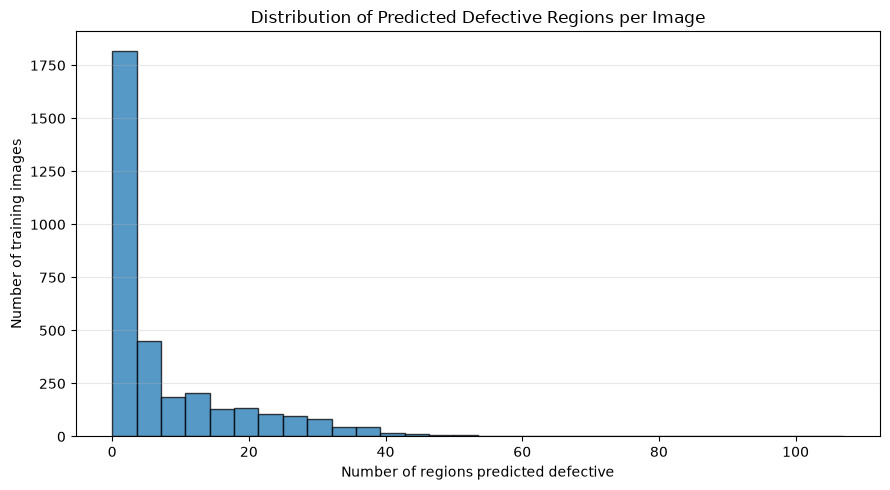

count    3349.000000
mean        7.760824
std        10.664418
min         0.000000
25%         0.000000
50%         3.000000
75%        11.000000
max       107.000000
Name: predicted_defect_count, dtype: float64


In [14]:

plt.figure(figsize=(9, 5))

# Plot how many training images contain different
# numbers of predicted defective regions.
plt.hist(
    image_predictions_df["predicted_defect_count"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.xlabel("Number of regions predicted defective")
plt.ylabel("Number of training images")
plt.title("Distribution of Predicted Defective Regions per Image")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display summary statistics.
print(
    image_predictions_df["predicted_defect_count"]
    .describe()
)


### Optimising

In [15]:
def extract_patches(image, patch_size=32):
    """
    Divide an RGB image into non-overlapping patches.

    Partial patches are retained along image boundaries.

    Parameters
    ----------
    image : PIL.Image.Image
        Original RGB image.

    patch_size : int
        Maximum patch width and height in pixels.

    Returns
    -------
    list of dict
        Patch coordinates, dimensions and RGB pixel arrays.
    """

    # Convert the RGB image to a NumPy array.
    image_array = np.array(image)

    # Retrieve the image dimensions.
    height, width, channels = image_array.shape

    # Initialise the list of extracted patches.
    patches_list = []

    # Traverse the full image in patch-sized increments.
    for y in range(0, height, patch_size):
        for x in range(0, width, patch_size):

            # Clip the final patches to the image boundaries.
            x_end = min(x + patch_size, width)
            y_end = min(y + patch_size, height)

            # Extract the patch's RGB pixels.
            patch_rgb = image_array[y:y_end, x:x_end]

            # Record the patch and its position.
            patches_list.append({
                "x": x,
                "y": y,
                "width": x_end - x,
                "height": y_end - y,
                "rgb": patch_rgb
            })

    return patches_list

In [16]:
def extract_rgb_features(patch_rgb):
    """
    Calculate six RGB statistics for an image patch.

    Parameters
    ----------
    patch_rgb : numpy.ndarray
        RGB pixel array with shape (height, width, 3).

    Returns
    -------
    dict
        Mean and standard deviation for each RGB channel.
    """

    # Reshape the patch so each row represents one RGB pixel.
    pixels = patch_rgb.reshape(-1, 3)

    # Calculate channel-specific means and standard deviations.
    mean_rgb = pixels.mean(axis=0)
    std_rgb = pixels.std(axis=0)

    # Return the six numerical predictor features.
    return {
        "mean_r": mean_rgb[0],
        "mean_g": mean_rgb[1],
        "mean_b": mean_rgb[2],
        "std_r": std_rgb[0],
        "std_g": std_rgb[1],
        "std_b": std_rgb[2]
    }

In [17]:

from PIL import Image

# Paths for original training images and annotations.
TRAIN_DIR = Path("../data/raw/train")
TRAIN_COCO_PATH = TRAIN_DIR / "_annotations.coco.json"

# Load the training annotations.
with open(TRAIN_COCO_PATH, "r") as f:
    train_coco = json.load(f)

train_images = train_coco["images"]
train_annotations = train_coco["annotations"]

# Identify images containing at least one annotated defect.
annotated_image_ids = {
    annotation["image_id"]
    for annotation in train_annotations
}

print(f"Training images: {len(train_images)}")
print(f"Training annotations: {len(train_annotations)}")


Training images: 3349
Training annotations: 2923


In [18]:

# Store one prediction record per original training image.
training_image_records = []

for image_info in train_images:

    image_id = image_info["id"]
    filename = image_info["file_name"]

    # Load the original RGB image.
    image_path = TRAIN_DIR / filename

    with Image.open(image_path) as img:
        image = img.convert("RGB")

        # Extract all patches, including ambiguous and edge patches.
        patches = extract_patches(
            image,
            patch_size=32
        )

    # Extract the existing six RGB features for each patch.
    patch_features = pd.DataFrame([
        extract_rgb_features(patch["rgb"])
        for patch in patches
    ])[FEATURE_COLS]

    # Predict strict binary classifications for every patch.
    # 0 = NON-DEFECT, 1 = DEFECT
    patch_predictions = nn_pipeline.predict(patch_features)

    # Count the total number of predicted defective patches.
    defective_count = int(np.sum(patch_predictions))

    # Assign ground truth using the original COCO annotations.
    actual_label = int(image_id in annotated_image_ids)

    training_image_records.append({
        "image_id": image_id,
        "filename": filename,
        "total_regions": len(patches),
        "predicted_defect_count": defective_count,
        "actual_label": actual_label
    })

# Create the complete image-level training dataset.
train_image_df = pd.DataFrame(training_image_records)

print(f"Images processed: {len(train_image_df)}")

print("\nRegion counts per image:")
print(train_image_df["total_regions"].describe())

display(train_image_df.head(10))


Images processed: 3349

Region counts per image:
count    3349.0
mean      391.0
std         0.0
min       391.0
25%       391.0
50%       391.0
75%       391.0
max       391.0
Name: total_regions, dtype: float64


,image_id,filename,total_regions,predicted_defect_count,actual_label
0,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,391,2,1
1,1,frame_with_red_1237_jpg.rf.7c920cb9b9d7c993551...,391,7,1
2,2,frame_with_red_6884_jpg.rf.73d4cccf385f78c6473...,391,3,1
3,3,frame_with_red_2737_jpg.rf.8af748cd8904c67c7a0...,391,3,0
4,4,frame_with_red_10465_jpg.rf.800ed5e3f0775757ce...,391,0,1
5,5,frame_with_red_4731_jpg.rf.3a77f43a67d47e5af7c...,391,1,0
6,6,frame_with_red_6730_jpg.rf.89f6a482f350a46b8b6...,391,2,1
7,7,frame_with_red_6061_jpg.rf.82a611ae235c53956a6...,391,14,1
8,8,frame_with_red_4352_jpg.rf.995114ca4546bb090eb...,391,25,1
9,9,frame_with_red_6205_jpg.rf.a4b1966ef4b87fe8081...,391,15,1


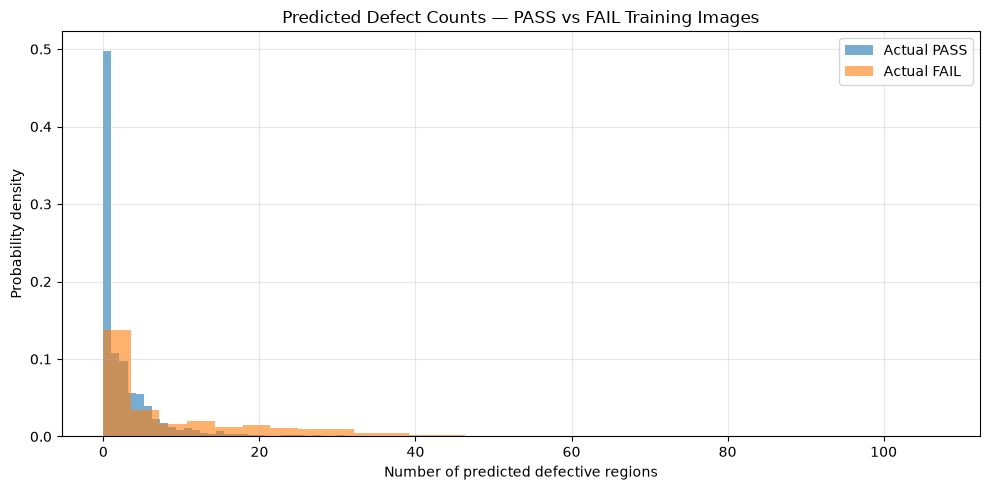

PASS images:
count    684.000000
mean       2.814327
std        3.996232
min        0.000000
25%        0.000000
50%        1.000000
75%        4.000000
max       31.000000
Name: predicted_defect_count, dtype: float64

FAIL images:
count    2665.000000
mean        9.256285
std        11.603367
min         0.000000
25%         1.000000
50%         4.000000
75%        15.000000
max       107.000000
Name: predicted_defect_count, dtype: float64


In [19]:

# Separate images by their actual COCO classification.
pass_counts = train_image_df.loc[
    train_image_df["actual_label"] == 0,
    "predicted_defect_count"
]

fail_counts = train_image_df.loc[
    train_image_df["actual_label"] == 1,
    "predicted_defect_count"
]

plt.figure(figsize=(10, 5))

# Compare predicted defective-region distributions.
plt.hist(
    pass_counts,
    bins=30,
    alpha=0.6,
    label="Actual PASS",
    density=True
)

plt.hist(
    fail_counts,
    bins=30,
    alpha=0.6,
    label="Actual FAIL",
    density=True
)

plt.xlabel("Number of predicted defective regions")
plt.ylabel("Probability density")
plt.title("Predicted Defect Counts — PASS vs FAIL Training Images")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display statistics separately for each class.
print("PASS images:")
print(pass_counts.describe())

print("\nFAIL images:")
print(fail_counts.describe())


In [21]:
from sklearn.metrics import recall_score
# Test every integer count threshold from zero
# up to the maximum observed predicted defect count.
max_count = int(train_image_df["predicted_defect_count"].max())

failure_thresholds = range(0, max_count + 1)

# Actual training-image labels.
y_true = train_image_df["actual_label"]

# Store the results of each decision threshold.
threshold_results = []

for max_defects in failure_thresholds:

    # An image FAILS if the count strictly exceeds the threshold.
    y_pred = (
        train_image_df["predicted_defect_count"] > max_defects
    ).astype(int)

    threshold_results.append({
        "max_defects": max_defects,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ),
        "fail_recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "pass_recall": recall_score(
            y_true, y_pred, pos_label=0, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

# Rank thresholds by balanced accuracy and then macro F1.
ranked_thresholds = threshold_results_df.sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
)

display(ranked_thresholds.head(15).round(3))


,max_defects,accuracy,balanced_accuracy,macro_f1,fail_recall,pass_recall
6,6,0.511,0.650,0.500,0.416,0.883
7,7,0.495,0.648,0.487,0.389,0.906
8,8,0.481,0.646,0.475,0.367,0.924
5,5,0.526,0.643,0.509,0.444,0.842
9,9,0.469,0.643,0.465,0.349,0.937
10,10,0.456,0.638,0.453,0.330,0.946
11,11,0.441,0.633,0.440,0.309,0.958
4,4,0.538,0.630,0.515,0.474,0.785
12,12,0.429,0.629,0.428,0.291,0.966
13,13,0.417,0.623,0.417,0.275,0.971


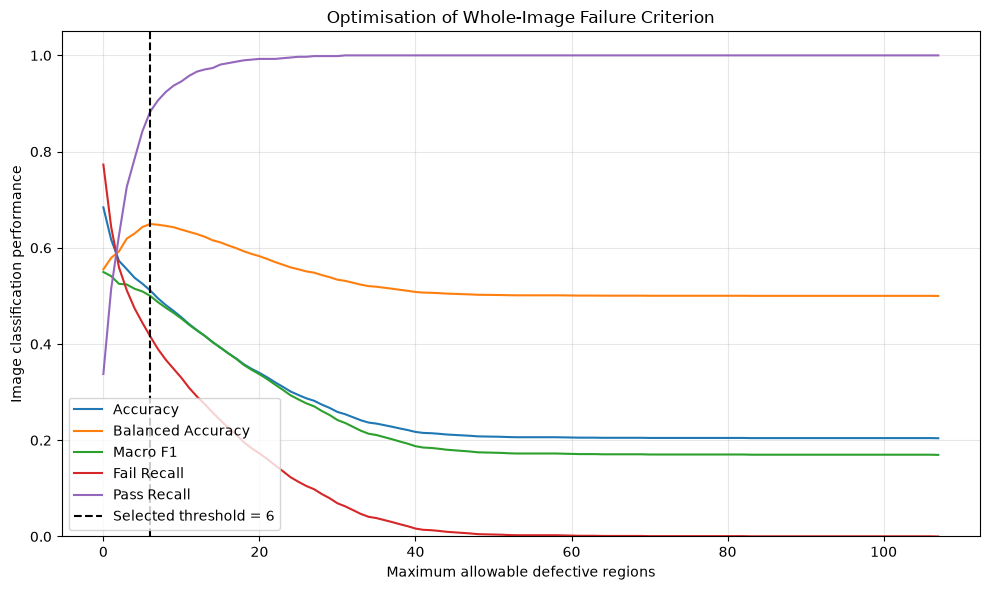

Selected defect-count threshold: 6
Training accuracy: 51.15%
Balanced accuracy: 64.96%
Macro F1: 0.500


In [22]:

plt.figure(figsize=(10, 6))

for metric in [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "fail_recall",
    "pass_recall"
]:
    plt.plot(
        threshold_results_df["max_defects"],
        threshold_results_df[metric],
        label=metric.replace("_", " ").title()
    )

# Identify the threshold giving maximum balanced accuracy.
best_result = ranked_thresholds.iloc[0]
BEST_MAX_DEFECTS = int(best_result["max_defects"])

plt.axvline(
    BEST_MAX_DEFECTS,
    linestyle="--",
    color="black",
    label=f"Selected threshold = {BEST_MAX_DEFECTS}"
)

plt.xlabel("Maximum allowable defective regions")
plt.ylabel("Image classification performance")
plt.title("Optimisation of Whole-Image Failure Criterion")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Selected defect-count threshold: {BEST_MAX_DEFECTS}")
print(f"Training accuracy: {best_result['accuracy']:.2%}")
print(f"Balanced accuracy: {best_result['balanced_accuracy']:.2%}")
print(f"Macro F1: {best_result['macro_f1']:.3f}")


In [23]:
# Create the models directory if required.
MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Save the trained neural network and its scaler.
joblib.dump(nn_pipeline, MODEL_PATH)

# Store the selected whole-image failure criterion.
threshold_config = {
    "max_defects": BEST_MAX_DEFECTS,
    "patch_size": 32,
    "selection_metric": "balanced_accuracy",
    "selection_dataset": "training",
    "region_classification": "binary"
}

# Save configuration as JSON.
with open(THRESHOLD_PATH, "w") as f:
    json.dump(threshold_config, f, indent=4)

print(f"Model saved to: {MODEL_PATH}")
print(f"Failure criterion saved to: {THRESHOLD_PATH}")
print(f"Selected maximum defects: {BEST_MAX_DEFECTS}")


Model saved to: ..\models\binary_region_nn.joblib
Failure criterion saved to: ..\models\binary_region_nn_threshold.json
Selected maximum defects: 6


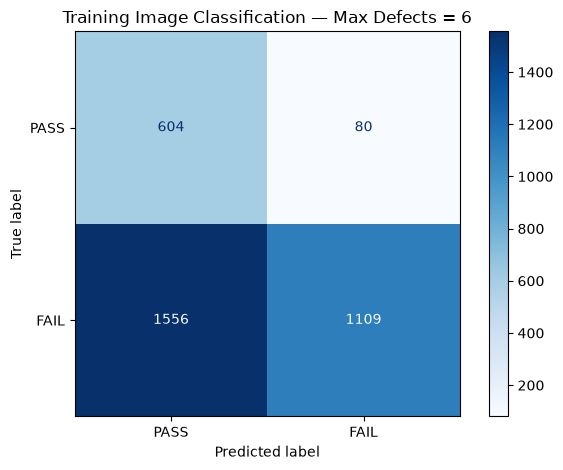

In [24]:
# Predict image-level PASS/FAIL classifications.
# 0 = PASS, 1 = FAIL.
y_true = train_image_df["actual_label"]

y_pred = (
    train_image_df["predicted_defect_count"] > BEST_MAX_DEFECTS
).astype(int)

# Calculate the confusion matrix.
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["PASS", "FAIL"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title(
    f"Training Image Classification — Max Defects = {BEST_MAX_DEFECTS}"
)

plt.tight_layout()
plt.show()
